# 287: does combining kmerseek calls with BLAST's sum statistics rescue Ced9 → BCL2?

**Question.** kmerseek scores each ungapped call (a stretch matched without gaps) alone. On
BCL2, Ced9 has two calls that sit on UniProt's BH4 and BH1 motifs, in the same order on both
proteins ([notebook 284's table](284_ced9_bcl2_family_hits.csv), [PR 125](https://github.com/seanome/2024-kmerseek-analysis/pull/125)):

| motif | Ced9 (1-based) | BCL2 (1-based) | setting | E-value |
|---|---|---|---|---|
| BH4 | 78-99 | 9-30 | wwmj5, k = 9 | 1_955 |
| BH1 | 163-188 | 139-164 | hp_lehninger2, k = 19 | 11_173 |

Neither call alone is better than chance, and they sit on different diagonals (target start
minus query start is -69 for BH4 and -24 for BH1) because BCL2 has 45 more residues than
Ced9 between the two motifs (109 against 64). BLAST combines several such hits into one E-value with sum
statistics. If kmerseek did the same, where would BCL2 rank among human proteins for the
query Ced9, and CD47 for the query P66, and would shuffled copies of the queries score as
well?

**Decision this informs.** Whether to ask kmerseek to combine calls across alphabets (an
issue in seanome/kmerseek), and whether the paper can show Ced9 → BCL2 as a pair kmerseek
finds once its calls are combined.

**Data.** Notebook 241's search ([PR 46](https://github.com/seanome/2024-kmerseek-analysis/pull/46)):
queries Ced9 (280 aa), P66 (597 aa) and BHF (252 aa) against the GENCODE v49 canonical human
proteome (one protein per gene), kmerseek 982a055, 152 alphabet-k settings, every region
kept (`/Users/olga/data/botryllus/alphabet-ranking-three-cases/regions.parquet`). 71 of the
152 settings have a fitted E-value; the other 81 report E = infinity and cannot join a chain.
Coordinates are kmerseek's: 0-based, end-exclusive; tables below print 1-based.

**The formula** (Karlin & Altschul 1993, equation 4; Altschul & Gish 1996 for the order rule;
as NCBI BLAST implements it in `blast_stat.c`, `BLAST_LargeGapSumE`). Each call $i$ gets a
score in natural-log units for this one protein pair, from its own $\lambda_i$ and $K$:

$$y_i = \lambda_i S_i - \ln K - \ln(m\,n_t) = \ln\frac{N}{n_t\,E_i}$$

with $S_i$ its raw score, $m$ the query length, $n_t$ the target length, $N$ the number of
k-mers in the human index ("total k-mers found" when it was built) and $E_i$ kmerseek's
E-value. For $r$ calls in the same order on both proteins,

$$s = \sum_{i=1}^{r} y_i + \ln r!, \qquad P = \Pr(r, s) \approx \frac{e^{-s}\, s^{r-1}}{r!\,(r-1)!}$$

($\Pr(r,s)$ computed from Karlin & Altschul's exact double integral; the right-hand form
holds for large $s$), and the chain's E-value over the whole proteome is

$$E_{\text{chain}} = -\ln(1-P)\;\frac{N}{n_t}\;2^{\,r-1}.$$

$\ln r!$ is the order rule: of the $r!$ orders in which $r$ chance hits can fall, only one is
the same on both proteins. $2^{r-1}$ is BLAST's price for picking a set of $r$ hits out of
all possible sets (gap-decay rate 0.5, BLAST's default for ungapped search). A chain of one
call gets back kmerseek's own E-value.

**Rules, fixed before running (2026-10-13).**

1. *Which calls may join.* Calls with a fitted E-value and a positive score for this pair
   ($y_i > 0$, that is $E_i < N/n_t$, about 44_000 for BCL2). BLAST links only hits above a
   score cutoff; kmerseek's own `chain_regions` takes only positive ones.
2. *Order and gap.* Each call starts after the previous one ends, on both proteins: no
   overlap. The next call starts at most **200 residues** after the previous one ends, on
   each protein. This cap was set after reading that BH4 to BH1 is 64 residues on Ced9 and
   109 on BCL2, so it is not blind to them; 50, 100 and 400 are run too. The formula above
   does not use the cap: it counts each extra call as free to start anywhere on the pair.
   The diagonal may shift by any amount.
3. *Different alphabets in one chain: yes.* Raw scores from two alphabets are in different
   units, but $y_i$ uses each call's own $\lambda_i$ and $K$, so every $y_i$ has the same
   chance distribution. A chain may also be all from one setting; that version (what
   kmerseek's existing `--chain-max-gap` does inside one search, with BLAST's order rule
   here) is reported beside it.
4. *Search space.* Each call is the best of 71 searches (one per setting with an E-value).
   So every call's E-value is multiplied by 71 before it joins a chain ($y_i - \ln 71$), and
   the lowest single E-value is multiplied by 71 too. This is the **main score**. The same
   numbers without the factor of 71 are reported beside it.

   *Corrected 2026-10-20:* this rule first said 69, the settings in which one of the three
   real queries got a finite E-value. 71 settings have an E-value fit (notebook 241's
   `arms.csv`); gbmr4 k21 and hp_lehninger_hpc3 k25 gave none of the real queries a finite
   E-value, but a shuffled copy of Ced9 got one. The factor counts every setting searched
   with a fit, so it is 71. It raises every main-score E-value by 71/69, about 3%.
5. *A protein's score* is its lowest chain E-value; a chain may be one call.

**Decision rule.** Ced9 → BCL2 is rescued if, with the main score:
(a) BCL2 is in the top 20 of the human proteome and its chain E-value is below 1, and
(b) on dipeptide-shuffled copies of Ced9 (each keeps Ced9's length and the count of every
adjacent residue pair, so it keeps composition and short repeats but has no homology),
BCL2 gets a chain E-value below 1 in at most 5% of copies, and
(c) the main score is calibrated: across shuffled copies, the mean number of human proteins
with chain E-value below 1 is between 0.3 and 3 (a calibrated E-value gives 1).
The same rule for P66 → CD47. Until the shuffled searches exist, (c) is checked on the real
searches: proteins outside the known family (for Ced9: HGNC gene groups 1057, BCL2 family,
and 1277, BH3-only; for P66: CD47; for BHF: none) with chain E-value below 1 should number
about 1 per search and at most 3.

On the Pfam 998 all-against-all, chaining helps if the chain score's average precision is at
least 0.01 higher than the lowest single E-value's.

Lower E-value is better; E-value 1 means one hit this good is expected by chance in a search
of the whole proteome.

In [1]:
import json
import math
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import polars as pl
from matplotlib.patches import Polygon, Rectangle

import hp_conservation_utils as hcu
import pubfig as pf
import sum_statistics_utils as ss

pf.use_style()
pl.Config.set_tbl_rows(60)
pl.Config.set_tbl_cols(30)
pl.Config.set_tbl_width_chars(220)
pl.Config.set_fmt_str_lengths(90)
pl.Config.set_float_precision(3)

D = Path("/Users/olga/data/botryllus/alphabet-ranking-three-cases")
HUMAN = Path(
    "/Users/olga/data/gencode/human/v49/gencode.v49.pc_translations.canonical.fa"
)
FIG = Path("../figures")
TOOLS = "kmerseek 982a055 (notebook 241's search), 152 alphabet-k settings, 71 with an E-value fit"
SINGLE = dict(
    marker="o", color=pf.OKABE_ITO["blue"], label="lowest single-call E-value"
)
CHAIN = dict(
    marker="D", color=pf.OKABE_ITO["vermillion"], label="chain E-value (sum statistic)"
)


def read_fasta(p):
    out, name = {}, None
    for line in open(p):
        if line.startswith(">"):
            name = line[1:].strip()
            out[name] = []
        else:
            out[name].append(line.strip())
    return {k: "".join(v) for k, v in out.items()}


queries = read_fasta(D / "queries.fa")
human = {h.split("|")[6]: s for h, s in read_fasta(HUMAN).items()}
# mmseqs12 is not in hp_conservation_utils; classes from kmerseek 982a055 src/rust/alphabets.rs
CLUSTERS = hcu.ALPHABET_CLUSTERS | {
    "mmseqs12": ["AST", "LM", "IV", "KR", "EQ", "ND", "FY", "C", "G", "H", "P", "W"]
}
uniprot = {
    a: json.load(open(D / f"287/uniprot/{a}.json")) for a in ("Q08722", "H7C7N8")
}
assert (
    uniprot["Q08722"]["sequence"]["value"] == human["CD47"]
), "GENCODE CD47 differs from UniProt Q08722"
assert (
    uniprot["H7C7N8"]["sequence"]["value"][21:] == queries["P66"]
), "query P66 is not H7C7N8 without its signal peptide"
print({q: len(s) for q, s in queries.items()}, "human proteins:", len(human))

{'Ced9': 280, 'P66': 597, 'BHF': 252} human proteins: 19705


## 1. Ced9's BH4 and BH1 calls on BCL2, scored as one chain

The two calls notebook 284 found in register with UniProt's motifs, residue by residue. `|`
marks an identical residue; under each pair, the same stretch written in the call's own
alphabet (one letter per class), with `|` where the classes agree, which is what kmerseek
matched. Then the chain's E-value under each way of counting the search.

In [2]:
def encode(seq, alphabet):
    """One letter per class (a, b, c, ...), in the order of the alphabet's class list."""
    table = {
        r: chr(ord("a") + i) for i, cl in enumerate(CLUSTERS[alphabet]) for r in cl
    }
    return "".join(table.get(r, "?") for r in seq)


def show_call(query, q_seq, q_start, target, t_seq, t_start, length, setting):
    """Print one ungapped call: residues, identity line, and the encoded strings.
    Starts are 1-based."""
    alphabet = setting.rsplit(".k", 1)[0]
    a = q_seq[q_start - 1 : q_start - 1 + length]
    b = t_seq[t_start - 1 : t_start - 1 + length]
    ea, eb = encode(a, alphabet), encode(b, alphabet)
    same = "".join("|" if x == y else " " for x, y in zip(a, b))
    same_class = "".join("|" if x == y else " " for x, y in zip(ea, eb))
    w = 22  # wide enough for "(hp_kyte_doolittle2)", the longest alphabet name shown
    print(
        f"{setting}, {length} residues, {same.count('|')} identical, {same_class.count('|')} in the same class"
    )
    print(f"  {query:<{w}}{q_start:>4} {a} {q_start + length - 1}")
    print(f"  {'':<{w}}     {same}")
    print(f"  {target:<{w}}{t_start:>4} {b} {t_start + length - 1}")
    print(f"  {'(' + alphabet + ')':<{w}}     {ea}")
    print(f"  {'':<{w}}     {same_class}")
    print(f"  {'':<{w}}     {eb}")
    print()


named = pl.read_csv("287_named_chain_human.csv")
print("BH4 call (on BCL2's BH4):")
show_call("Ced9", queries["Ced9"], 78, "BCL2", human["BCL2"], 9, 22, "wwmj5.k9")
print("BH1 call (on BCL2's BH1):")
show_call(
    "Ced9", queries["Ced9"], 163, "BCL2", human["BCL2"], 139, 26, "hp_lehninger2.k19"
)
named.select("variant", "settings_factor", "e_bh4", "e_bh1", "chain_e")

BH4 call (on BCL2's BH4):
wwmj5.k9, 22 residues, 7 identical, 17 in the same class
  Ced9                    78 LDIEGFVVDYFTHRIRQNGMEW 99
                              |    |  |      | | ||
  BCL2                     9 YDNREIVMKYIHYKLSQRGYEW 30
  (wwmj5)                    adadcaaadaabbeaeeecada
                             ||   ||| ||| |||||||||
                             adeedaaaeaabaeaeeecada

BH1 call (on BCL2's BH1):
hp_lehninger2.k19, 26 residues, 5 identical, 24 in the same class
  Ced9                   163 QCPMSYGRLIGLISFGGFVAAKMMES 188
                                   ||      |||         
  BCL2                   139 RDGVNWGRIVAFFEFGGVMCVESVNR 164
  (hp_lehninger2)            bbaabaabaaaaabaaaaaaabaabb
                             ||||||||||||||||||| || |||
                             bbaabaabaaaaabaaaaababbabb



variant,settings_factor,e_bh4,e_bh1,chain_e
str,i64,f64,f64,f64
"""across settings, x71""",71,138779.180,793261.227,422827.429
"""across settings, no factor""",1,1954.636,11172.693,1279.954
"""one setting, x71""",71,138779.180,793261.227,422827.429
"""one setting, no factor""",1,1954.636,11172.693,1279.954


The figure draws both proteins as a line with UniProt's BH motifs as boxes, and each call
as a bar joined to its partner stretch. The third call (hp_pbotc_1st_ed2, k = 16) is the one
the search itself picks to join BH4 when the factor of 71 is left out (section 2): it is not
on any BH motif on either protein, and it overlaps the BH1 call on BCL2, so the two cannot
be in one chain.

shape: (3, 4)
┌───────────────────────────────────────────────────────────┬─────────┬─────────┬────────┐
│ call                                                      ┆ ced9    ┆ bcl2    ┆ offset │
│ ---                                                       ┆ ---     ┆ ---     ┆ ---    │
│ str                                                       ┆ str     ┆ str     ┆ i64    │
╞═══════════════════════════════════════════════════════════╪═════════╪═════════╪════════╡
│ BH4 call: wwmj5, k = 9, E = 1_955                         ┆ 78-99   ┆ 9-30    ┆ -69    │
│ BH1 call: hp_lehninger2, k = 19, E = 11_173               ┆ 163-188 ┆ 139-164 ┆ -24    │
│ call off the motifs: hp_pbotc_1st_ed2, k = 16, E = 10_209 ┆ 109-126 ┆ 124-141 ┆ 15     │
└───────────────────────────────────────────────────────────┴─────────┴─────────┴────────┘


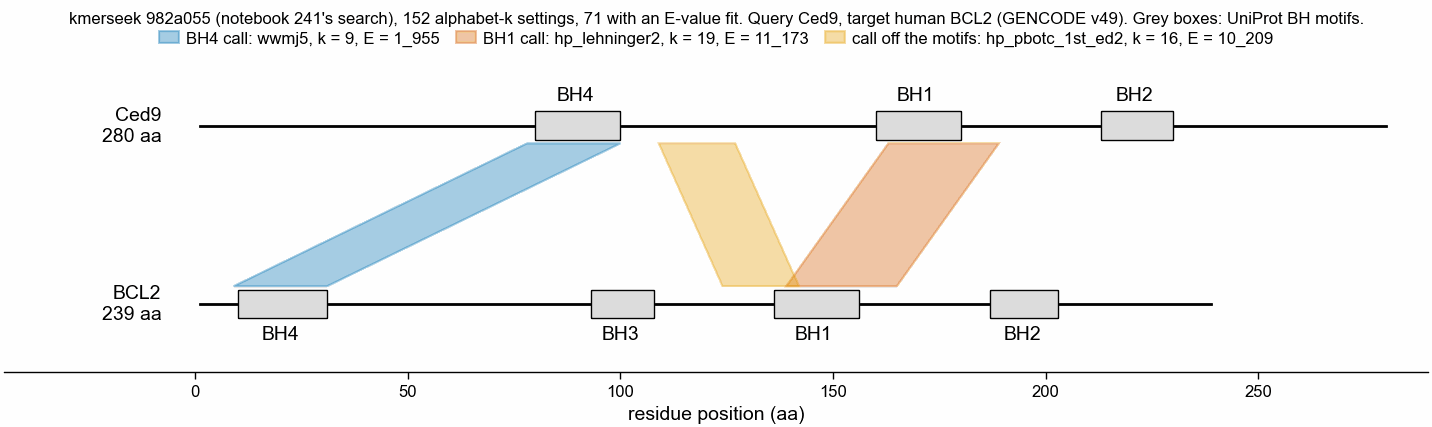

In [3]:
# UniProt BH motifs, 1-based, as notebook 284 fetched them (P41958 CED-9, P10415 BCL2)
MOTIFS = {
    "Ced9": {"BH4": (80, 99), "BH1": (160, 179), "BH2": (213, 229)},
    "BCL2": {"BH4": (10, 30), "BH3": (93, 107), "BH1": (136, 155), "BH2": (187, 202)},
}
members = pl.read_csv("287_chain_members_human.csv")
pbotc = members.filter(
    (pl.col("query") == "Ced9")
    & (pl.col("variant") == "across settings, no factor")
    & (pl.col("setting") == "hp_pbotc_1st_ed2.k16")
).row(0, named=True)
CALLS_CED9 = [
    # (label, Ced9 start, BCL2 start, length, colour), 1-based starts
    ("BH4 call: wwmj5, k = 9, E = 1_955", 78, 9, 22, pf.OKABE_ITO["blue"]),
    (
        "BH1 call: hp_lehninger2, k = 19, E = 11_173",
        163,
        139,
        26,
        pf.OKABE_ITO["vermillion"],
    ),
    (
        f"call off the motifs: hp_pbotc_1st_ed2, k = 16, E = {pbotc['evalue']:_.0f}",
        pbotc["query_start"],
        pbotc["target_start"],
        pbotc["query_end"] - pbotc["query_start"] + 1,
        pf.OKABE_ITO["orange"],
    ),
]


def draw_pair(
    ax,
    top,
    top_len,
    bottom,
    bottom_len,
    top_boxes,
    bottom_boxes,
    calls,
    box_colour="#DDDDDD",
):
    """Two proteins as lines with domain boxes; each call a bar on both, joined by a band."""
    y_top, y_bot, h = 1.0, 0.0, 0.16
    for y, name, n, boxes in (
        (y_top, top, top_len, top_boxes),
        (y_bot, bottom, bottom_len, bottom_boxes),
    ):
        ax.plot([1, n], [y, y], color="black", lw=1)
        for lab, (s, e) in boxes.items():
            ax.add_patch(
                Rectangle(
                    (s, y - h / 2),
                    e - s + 1,
                    h,
                    facecolor=box_colour,
                    edgecolor="black",
                    lw=0.5,
                    zorder=2,
                )
            )
            ax.text(
                (s + e) / 2,
                y + (h / 2 + 0.04) * (1 if y == y_top else -1),
                lab,
                ha="center",
                va="bottom" if y == y_top else "top",
            )
        ax.text(-8, y, f"{name}\n{n} aa", ha="right", va="center")
    for lab, qs, ts, n, col in calls:
        ax.add_patch(
            Polygon(
                [
                    (qs, y_top - h / 2 - 0.02),
                    (qs + n, y_top - h / 2 - 0.02),
                    (ts + n, y_bot + h / 2 + 0.02),
                    (ts, y_bot + h / 2 + 0.02),
                ],
                closed=True,
                facecolor=col,
                alpha=0.35,
                edgecolor=col,
                lw=0.8,
                label=lab,
                zorder=1,
            )
        )
    ax.set_ylim(-0.38, 1.3)
    ax.set_yticks([])
    ax.spines["left"].set_visible(False)
    ax.set_xlabel("residue position (aa)")


fig, ax = pf.figure(pf.TWO_COLUMN_MM, 55)
draw_pair(
    ax,
    "Ced9",
    len(queries["Ced9"]),
    "BCL2",
    len(human["BCL2"]),
    MOTIFS["Ced9"],
    MOTIFS["BCL2"],
    CALLS_CED9,
)
ax.set_xlim(-45, 290)
pf.shared_legend(
    fig,
    ncol=3,
    title=f"{TOOLS}. Query Ced9, target human BCL2 (GENCODE v49). Grey boxes: UniProt BH motifs.",
)
pf.save(fig, FIG / "287_ced9_bcl2_calls_human_gencode")
print(
    pl.DataFrame(
        [
            dict(
                call=c[0],
                ced9=f"{c[1]}-{c[1] + c[3] - 1}",
                bcl2=f"{c[2]}-{c[2] + c[3] - 1}",
                offset=c[2] - c[1],
            )
            for c in CALLS_CED9
        ]
    )
)

## 2. Where BCL2 and CD47 rank among 19_732 human proteins

For each way of counting, the partner's rank by its lowest single-call E-value and by its
chain E-value (rank 1 is the lowest E-value; ties share the best rank, and `n_tied_*` counts
them). `chain_e_of_rank_20` is the E-value the 20th protein reaches: what BCL2 or CD47
would need to be in the top 20. The main score is "across settings, x71".

shape: (8, 11)
┌───────┬─────────┬────────────────────────────┬────────────┬─────────┬────────────┬──────────────┬────────────┬─────────────┬───────────────┬────────────────────┐
│ query ┆ partner ┆ variant                    ┆ chain_e    ┆ chain_r ┆ rank_chain ┆ n_tied_chain ┆ single_e   ┆ rank_single ┆ n_tied_single ┆ chain_e_of_rank_20 │
│ ---   ┆ ---     ┆ ---                        ┆ ---        ┆ ---     ┆ ---        ┆ ---          ┆ ---        ┆ ---         ┆ ---           ┆ ---                │
│ str   ┆ str     ┆ str                        ┆ f64        ┆ i64     ┆ i64        ┆ i64          ┆ f64        ┆ i64         ┆ i64           ┆ f64                │
╞═══════╪═════════╪════════════════════════════╪════════════╪═════════╪════════════╪══════════════╪════════════╪═════════════╪═══════════════╪════════════════════╡
│ Ced9  ┆ BCL2    ┆ across settings, x71       ┆ 138779.180 ┆ 1       ┆ 12906      ┆ 1            ┆ 138779.180 ┆ 12906       ┆ 1             ┆ 92.982             │
│

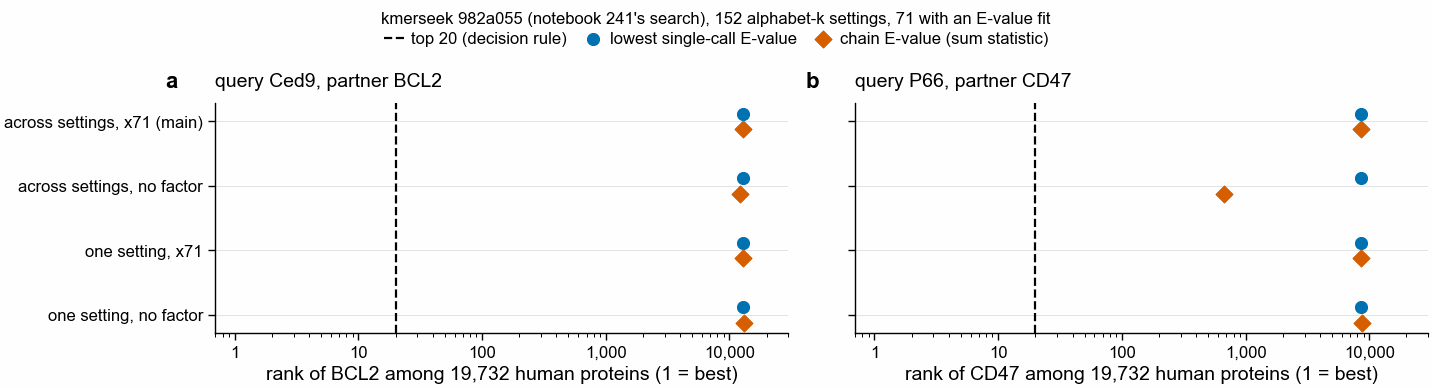

In [4]:
ranks = pl.read_csv("287_partner_rank_human.csv")
main4 = [
    "across settings, x71",
    "across settings, no factor",
    "one setting, x71",
    "one setting, no factor",
]
show = ranks.select(
    "query",
    "partner",
    "variant",
    "chain_e",
    "chain_r",
    "rank_chain",
    "n_tied_chain",
    "single_e",
    "rank_single",
    "n_tied_single",
    "chain_e_of_rank_20",
)
print(show.filter(pl.col("variant").is_in(main4)))
print(
    show.filter(~pl.col("variant").is_in(main4)).select(
        "query", "variant", "chain_e", "rank_chain"
    )
)

fig, axs = pf.figure(pf.TWO_COLUMN_MM, 50, ncols=2, sharey=True)
label_of = {
    "across settings, x71": "across settings, x71 (main)",
    "across settings, no factor": "across settings, no factor",
    "one setting, x71": "one setting, x71",
    "one setting, no factor": "one setting, no factor",
}
for ax, (q, p), letter in zip(axs, [("Ced9", "BCL2"), ("P66", "CD47")], "ab"):
    t = ranks.filter((pl.col("query") == q) & pl.col("variant").is_in(main4))
    yy = {v: i for i, v in enumerate(main4[::-1])}
    for v in main4:
        ax.axhline(yy[v], color="#DDDDDD", lw=0.3, zorder=0)
    ax.axvline(20, color="black", ls="--", lw=0.8, label="top 20 (decision rule)")
    for row in t.iter_rows(named=True):
        ax.scatter(
            row["rank_single"], yy[row["variant"]] + 0.12, s=18, zorder=3, **SINGLE
        )
        ax.scatter(
            row["rank_chain"], yy[row["variant"]] - 0.12, s=18, zorder=3, **CHAIN
        )
    ax.set_xscale("log")
    ax.set_xlim(0.7, 30_000)
    ax.set_xticks([1, 10, 100, 1000, 10000], ["1", "10", "100", "1,000", "10,000"])
    ax.set_yticks(list(yy.values()), [label_of[v] for v in yy])
    ax.set_xlabel(f"rank of {p} among 19,732 human proteins (1 = best)")
    ax.set_title(f"query {q}, partner {p}", loc="left")
    pf.panel_label(ax, letter)
pf.shared_legend(fig, ncol=3, title=TOOLS)
pf.save(fig, FIG / "287_partner_rank_by_score_human_gencode")

The whole proteome for Ced9, so BCL2's place can be seen against everything else: each
dot is one human protein, its lowest single-call E-value against its chain E-value. A dot
below the diagonal gained from chaining. Blue dots are the BCL-2 family (HGNC gene groups
1057 and 1277). The table under the figure lists every family member's two ranks.

shape: (2, 7)
┌────────────────────────────┬────────────┬───────────────────────┬────────────────────┬───────────────────┬───────────────┬──────────────┐
│ variant                    ┆ n_proteins ┆ n_lowered_by_chaining ┆ n_single_e_below_1 ┆ n_chain_e_below_1 ┆ bcl2_single_e ┆ bcl2_chain_e │
│ ---                        ┆ ---        ┆ ---                   ┆ ---                ┆ ---               ┆ ---           ┆ ---          │
│ str                        ┆ i64        ┆ i64                   ┆ i64                ┆ i64               ┆ f64           ┆ f64          │
╞════════════════════════════╪════════════╪═══════════════════════╪════════════════════╪═══════════════════╪═══════════════╪══════════════╡
│ across settings, no factor ┆ 18600      ┆ 8219                  ┆ 9                  ┆ 112               ┆ 1954.636      ┆ 1203.779     │
│ across settings, x71       ┆ 18600      ┆ 114                   ┆ 0                  ┆ 0                 ┆ 138779.180    ┆ 138779.180   │
└─────

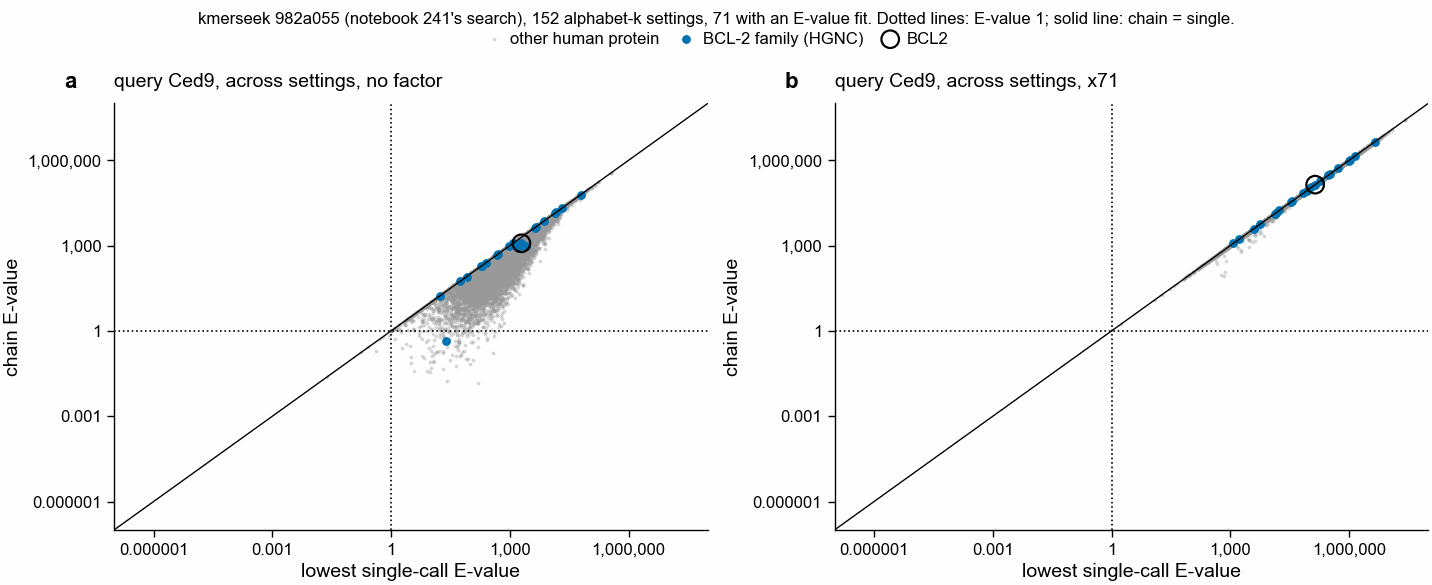

In [5]:
scores = pl.read_parquet(D / "287/chain_scores.parquet")
# HGNC gene group 1277 (BH3-only), saved response; group 1057 (BCL2 family) as listed in scripts/287_chain_scores.py
fam = {
    d["symbol"]
    for d in json.load(open(D / "287/hgnc_group_1277.json"))["response"]["docs"]
} | {
    "BAK1",
    "BAX",
    "BCL2",
    "BCL2A1",
    "BCL2L1",
    "BCL2L10",
    "BCL2L12",
    "BCL2L13",
    "BCL2L14",
    "BCL2L15",
    "BCL2L2",
    "BNIP2",
    "BOK",
    "MCL1",
}
fig, axs = pf.figure(pf.TWO_COLUMN_MM, 75, ncols=2)
ticks = [1e-6, 1e-3, 1, 1e3, 1e6]
tick_labels = ["0.000001", "0.001", "1", "1,000", "1,000,000"]
summary = []
for ax, v, letter in zip(
    axs, ["across settings, no factor", "across settings, x71"], "ab"
):
    s = scores.filter(
        (pl.col("query_name") == "Ced9") & (pl.col("variant") == v)
    ).with_columns(family=pl.col("gene").is_in(list(fam)))
    other, f = s.filter(~pl.col("family")), s.filter(pl.col("family"))
    ax.scatter(
        other["single_e"],
        other["chain_e"],
        s=2,
        color=pf.GREY,
        alpha=0.4,
        lw=0,
        label="other human protein",
        rasterized=True,
    )
    ax.scatter(
        f["single_e"],
        f["chain_e"],
        s=10,
        color=pf.OKABE_ITO["blue"],
        lw=0,
        label="BCL-2 family (HGNC)",
    )
    b = s.filter(pl.col("gene") == "BCL2").row(0, named=True)
    ax.scatter(
        b["single_e"],
        b["chain_e"],
        s=40,
        facecolor="none",
        edgecolor="black",
        lw=0.8,
        label="BCL2",
    )
    lo, hi = 1e-7, 1e8
    ax.plot([lo, hi], [lo, hi], color="black", lw=0.5)
    ax.axhline(1, color="black", ls=":", lw=0.6)
    ax.axvline(1, color="black", ls=":", lw=0.6)
    ax.set_xscale("log")
    ax.set_yscale("log")
    ax.set_xlim(lo, hi)
    ax.set_ylim(lo, hi)
    ax.set_xticks(ticks, tick_labels)
    ax.set_yticks(ticks, tick_labels)
    ax.set_xlabel("lowest single-call E-value")
    ax.set_ylabel("chain E-value")
    ax.set_title(f"query Ced9, {v}", loc="left")
    pf.panel_label(ax, letter)
    summary.append(
        dict(
            variant=v,
            n_proteins=s.height,
            n_lowered_by_chaining=int((s["chain_e"] < s["single_e"]).sum()),
            n_single_e_below_1=int((s["single_e"] < 1).sum()),
            n_chain_e_below_1=int((s["chain_e"] < 1).sum()),
            bcl2_single_e=b["single_e"],
            bcl2_chain_e=b["chain_e"],
        )
    )
pf.shared_legend(
    fig, ncol=3, title=f"{TOOLS}. Dotted lines: E-value 1; solid line: chain = single."
)
pf.save(fig, FIG / "287_ced9_single_vs_chain_evalue_human_gencode")
print(pl.DataFrame(summary))
# every BCL-2 family member with a call, both ways of counting
print(
    scores.filter(
        (pl.col("query_name") == "Ced9")
        & pl.col("variant").is_in(
            ["across settings, x71", "across settings, no factor"]
        )
        & pl.col("gene").is_in(list(fam))
    )
    .select(
        "variant", "gene", "single_e", "rank_single", "chain_e", "chain_r", "rank_chain"
    )
    .sort("variant", "rank_chain")
)

## 3. How many unrelated proteins reach E-value below 1 in one search

A calibrated E-value of 1 means one protein that good by chance per search of the whole
proteome. Every search here is one query against the proteome over all settings. The
proteins counted are outside the query's known family: for Ced9, outside HGNC gene groups
1057 and 1277; for P66, every protein but CD47; for BHF, every protein. Inside 0.3 to 3
(the grey band) counts as calibrated in the decision rule. These are real queries, not
shuffled copies; section 6 has the shuffled copies.

shape: (12, 5)
┌───────┬────────────────────────────┬───────────────────────────────────┬──────────────────────────────────┬──────────────────────────────────────────────────────────────────────────────────┐
│ query ┆ variant                    ┆ n_single_e_below_1_outside_family ┆ n_chain_e_below_1_outside_family ┆ genes_chain_e_below_1                                                            │
│ ---   ┆ ---                        ┆ ---                               ┆ ---                              ┆ ---                                                                              │
│ str   ┆ str                        ┆ i64                               ┆ i64                              ┆ str                                                                              │
╞═══════╪════════════════════════════╪═══════════════════════════════════╪══════════════════════════════════╪══════════════════════════════════════════════════════════════════════════════════╡
│ BHF   ┆ across set

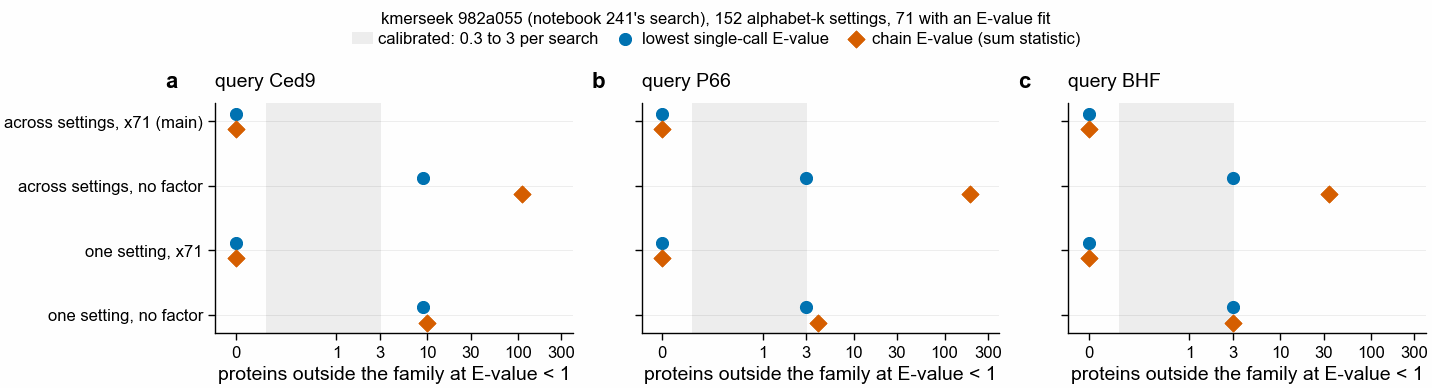

In [6]:
chance = pl.read_csv("287_chance_hits_human.csv").filter(pl.col("variant").is_in(main4))
print(
    chance.select(
        "query",
        "variant",
        "n_single_e_below_1_outside_family",
        "n_chain_e_below_1_outside_family",
        "genes_chain_e_below_1",
    ).with_columns(pl.col("genes_chain_e_below_1").str.slice(0, 80))
)
fig, axs = pf.figure(pf.TWO_COLUMN_MM, 50, ncols=3, sharey=True)
for ax, q, letter in zip(axs, ["Ced9", "P66", "BHF"], "abc"):
    t = chance.filter(pl.col("query") == q)
    yy = {v: i for i, v in enumerate(main4[::-1])}
    ax.axvspan(
        0.3, 3, color="#EEEEEE", zorder=0, label="calibrated: 0.3 to 3 per search"
    )
    for v in main4:
        ax.axhline(yy[v], color="#DDDDDD", lw=0.3, zorder=0)
    for row in t.iter_rows(named=True):
        ax.scatter(
            row["n_single_e_below_1_outside_family"],
            yy[row["variant"]] + 0.12,
            s=18,
            zorder=3,
            **SINGLE,
        )
        ax.scatter(
            row["n_chain_e_below_1_outside_family"],
            yy[row["variant"]] - 0.12,
            s=18,
            zorder=3,
            **CHAIN,
        )
    ax.set_xscale("symlog", linthresh=1)
    ax.set_xlim(-0.2, 400)
    ax.set_xticks(
        [0, 1, 3, 10, 30, 100, 300], ["0", "1", "3", "10", "30", "100", "300"]
    )
    ax.set_yticks(list(yy.values()), [label_of[v] for v in yy])
    ax.set_xlabel("proteins outside the family at E-value < 1")
    ax.set_title(f"query {q}", loc="left")
    pf.panel_label(ax, letter)
pf.shared_legend(fig, ncol=3, title=TOOLS)
pf.save(fig, FIG / "287_chance_hits_per_search_human_gencode")

## 4. Every chain the search picked for BCL2 and CD47, residue by residue

For each way of counting, the calls in the partner's best chain (a chain of one call is the
single best call). Coordinates 1-based; `offset` is target start minus query start, so calls
with different offsets sit on different diagonals.

In [7]:
partners = members.filter(pl.col("partner").is_in(["BCL2", "CD47"]))
print(
    partners.filter(pl.col("variant").is_in(main4)).select(
        "query",
        "partner",
        "variant",
        "member",
        "setting",
        "query_start",
        "query_end",
        "target_start",
        "target_end",
        "offset",
        "evalue",
        "y",
    )
)
for (q, p, v), g in partners.filter(pl.col("variant").is_in(main4)).group_by(
    ["query", "partner", "variant"], maintain_order=True
):
    print(f"=== {q} on {p}, {v}: {g.height} call(s)")
    for c in g.iter_rows(named=True):
        show_call(
            q,
            queries[q],
            c["query_start"],
            p,
            human[p],
            c["target_start"],
            c["query_end"] - c["query_start"] + 1,
            c["setting"],
        )

shape: (12, 12)
┌───────┬─────────┬────────────────────────────┬────────┬────────────────────────┬─────────────┬───────────┬──────────────┬────────────┬────────┬───────────┬───────┐
│ query ┆ partner ┆ variant                    ┆ member ┆ setting                ┆ query_start ┆ query_end ┆ target_start ┆ target_end ┆ offset ┆ evalue    ┆ y     │
│ ---   ┆ ---     ┆ ---                        ┆ ---    ┆ ---                    ┆ ---         ┆ ---       ┆ ---          ┆ ---        ┆ ---    ┆ ---       ┆ ---   │
│ str   ┆ str     ┆ str                        ┆ i64    ┆ str                    ┆ i64         ┆ i64       ┆ i64          ┆ i64        ┆ i64    ┆ f64       ┆ f64   │
╞═══════╪═════════╪════════════════════════════╪════════╪════════════════════════╪═════════════╪═══════════╪══════════════╪════════════╪════════╪═══════════╪═══════╡
│ Ced9  ┆ BCL2    ┆ across settings, x71       ┆ 1      ┆ wwmj5.k9               ┆ 78          ┆ 99        ┆ 9            ┆ 30         ┆ -69    ┆ 1954.636

The other BCL-2 family members whose best chain has two or more calls. All are from the
uncounted version (no factor of 71). BAK1 gains most: three calls take it from rank 468 to
rank 60, chain E-value 0.44.

In [8]:
others = members.filter(~pl.col("partner").is_in(["BCL2", "CD47"]))
print(
    others.select(
        "partner",
        "variant",
        "member",
        "setting",
        "query_start",
        "query_end",
        "target_start",
        "target_end",
        "offset",
        "evalue",
    )
)
for (p, v), g in others.group_by(["partner", "variant"], maintain_order=True):
    print(f"=== Ced9 on {p}, {v}: {g.height} calls")
    for c in g.iter_rows(named=True):
        show_call(
            "Ced9",
            queries["Ced9"],
            c["query_start"],
            p,
            human[p],
            c["target_start"],
            c["query_end"] - c["query_start"] + 1,
            c["setting"],
        )

shape: (8, 10)
┌─────────┬────────────────────────────┬────────┬────────────────────────┬─────────────┬───────────┬──────────────┬────────────┬────────┬───────────┐
│ partner ┆ variant                    ┆ member ┆ setting                ┆ query_start ┆ query_end ┆ target_start ┆ target_end ┆ offset ┆ evalue    │
│ ---     ┆ ---                        ┆ ---    ┆ ---                    ┆ ---         ┆ ---       ┆ ---          ┆ ---        ┆ ---    ┆ ---       │
│ str     ┆ str                        ┆ i64    ┆ str                    ┆ i64         ┆ i64       ┆ i64          ┆ i64        ┆ i64    ┆ f64       │
╞═════════╪════════════════════════════╪════════╪════════════════════════╪═════════════╪═══════════╪══════════════╪════════════╪════════╪═══════════╡
│ BAX     ┆ across settings, no factor ┆ 1      ┆ hp_kyte_doolittle2.k21 ┆ 71          ┆ 100       ┆ 33           ┆ 62         ┆ -38    ┆ 1564.435  │
│ BAX     ┆ across settings, no factor ┆ 2      ┆ hp_lehninger2.k16      ┆ 130       

P66 on CD47 drawn the same way: CD47 with UniProt Q08722's Ig-like V-type domain and its
five transmembrane helices, P66 (mature protein, UniProt H7C7N8 without its 21-residue signal
peptide) with the loop Tal et al. 2024 proposed as a CD47 mimic (UniProt 202-208, query
181-187). The four calls are the chain picked without the factor of 71.

shape: (4, 8)
┌────────┬────────────────────────┬─────────────┬───────────┬──────────────┬────────────┬────────┬───────────┐
│ member ┆ setting                ┆ query_start ┆ query_end ┆ target_start ┆ target_end ┆ offset ┆ evalue    │
│ ---    ┆ ---                    ┆ ---         ┆ ---       ┆ ---          ┆ ---        ┆ ---    ┆ ---       │
│ i64    ┆ str                    ┆ i64         ┆ i64       ┆ i64          ┆ i64        ┆ i64    ┆ f64       │
╞════════╪════════════════════════╪═════════════╪═══════════╪══════════════╪════════════╪════════╪═══════════╡
│ 1      ┆ hp_lehninger_hpc3.k14  ┆ 9           ┆ 38        ┆ 10           ┆ 39         ┆ 1      ┆ 707.354   │
│ 2      ┆ sdm12.k6               ┆ 102         ┆ 121       ┆ 86           ┆ 105        ┆ -16    ┆ 898.713   │
│ 3      ┆ hp_kyte_doolittle2.k17 ┆ 270         ┆ 292       ┆ 150          ┆ 172        ┆ -120   ┆ 4281.828  │
│ 4      ┆ mmseqs12.k5            ┆ 455         ┆ 470       ┆ 291          ┆ 306        ┆ -164   ┆

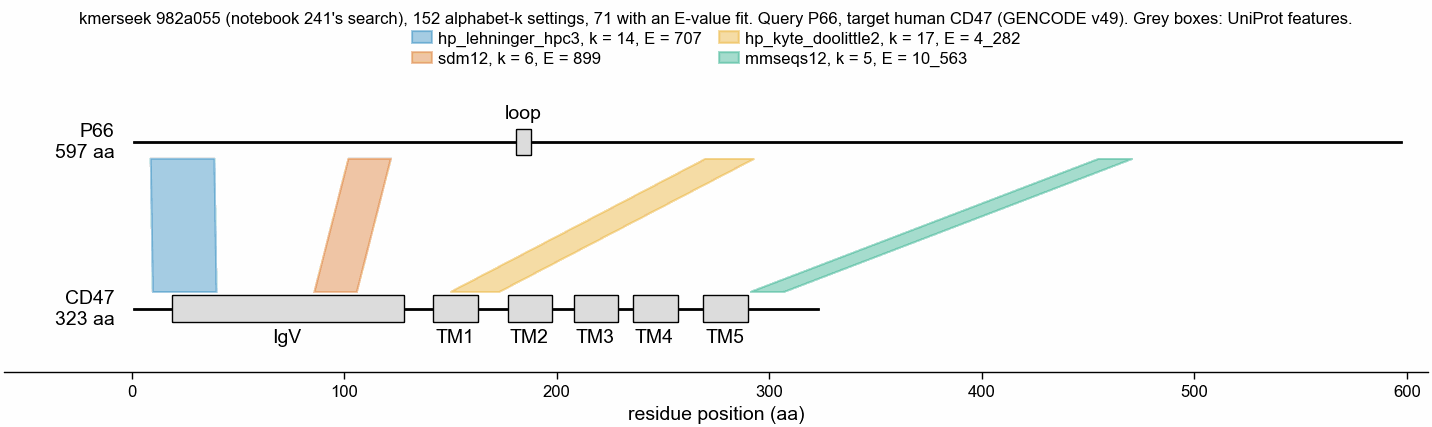

In [9]:
cd47_boxes = {"IgV": (19, 127)}
for i, f in enumerate(
    [f for f in uniprot["Q08722"]["features"] if f["type"] == "Transmembrane"]
):
    cd47_boxes[f"TM{i + 1}"] = (
        f["location"]["start"]["value"],
        f["location"]["end"]["value"],
    )
p66_boxes = {"loop": (181, 187)}
p66_chain = members.filter(
    (pl.col("query") == "P66") & (pl.col("variant") == "across settings, no factor")
)
cols = [pf.OKABE_ITO[c] for c in ("blue", "vermillion", "orange", "bluish_green")]
calls_p66 = [
    (
        f"{c['setting'].replace('.k', ', k = ')}, E = {c['evalue']:_.0f}",
        c["query_start"],
        c["target_start"],
        c["query_end"] - c["query_start"] + 1,
        col,
    )
    for c, col in zip(p66_chain.iter_rows(named=True), cols)
]
fig, ax = pf.figure(pf.TWO_COLUMN_MM, 55)
draw_pair(
    ax,
    "P66",
    len(queries["P66"]),
    "CD47",
    len(human["CD47"]),
    p66_boxes,
    cd47_boxes,
    calls_p66,
)
ax.set_xlim(-60, 610)
pf.shared_legend(
    fig,
    ncol=2,
    title=f"{TOOLS}. Query P66, target human CD47 (GENCODE v49). Grey boxes: UniProt features.",
)
pf.save(fig, FIG / "287_p66_cd47_chain_human_gencode")
print(
    p66_chain.select(
        "member",
        "setting",
        "query_start",
        "query_end",
        "target_start",
        "target_end",
        "offset",
        "evalue",
    )
)

## 5. Pfam 998 all-against-all: chain E-value against the lowest single E-value

Notebook 243's search of the 998 Pfam-annotated human proteins against themselves
([PR 48](https://github.com/seanome/2024-kmerseek-analysis/pull/48)), self matches dropped,
70 settings with an E-value, so each call's E-value is multiplied by 70 (the main score).
Each protein pair is ranked by its best chain and, separately, by its best single call.
Two labels: "placement" is notebook 284's rule (a Pfam family covers at least 20% of the
reported stretch on both proteins; a chain reports the stretch from its first call's start
to its last call's end); "shared Pfam family" asks only whether the two proteins share a
family, so both scores are judged on the same label. Average precision is the mean of the
precision at each correct pair, pairs sorted best first; higher is better.

shape: (2, 12)
┌──────────────────────┬─────────┬───────────────────┬─────────┬─────────────────┬──────────────────┬──────────┬───────────┬─────────────────────────┬──────────────────────────┬──────────────────────────┬───────────────┐
│ label                ┆ n_pairs ┆ n_settings_factor ┆ max_gap ┆ n_correct_chain ┆ n_correct_single ┆ ap_chain ┆ ap_single ┆ n_pairs_chain_e_below_1 ┆ n_pairs_single_e_below_1 ┆ n_pairs_chain_of_2_or_mo ┆ ap_difference │
│ ---                  ┆ ---     ┆ ---               ┆ ---     ┆ ---             ┆ ---              ┆ ---      ┆ ---       ┆ ---                     ┆ ---                      ┆ re                       ┆ ---           │
│ str                  ┆ i64     ┆ i64               ┆ i64     ┆ i64             ┆ i64              ┆ f64      ┆ f64       ┆ i64                     ┆ i64                      ┆ ---                      ┆ f64           │
│                      ┆         ┆                   ┆         ┆                 ┆                  ┆

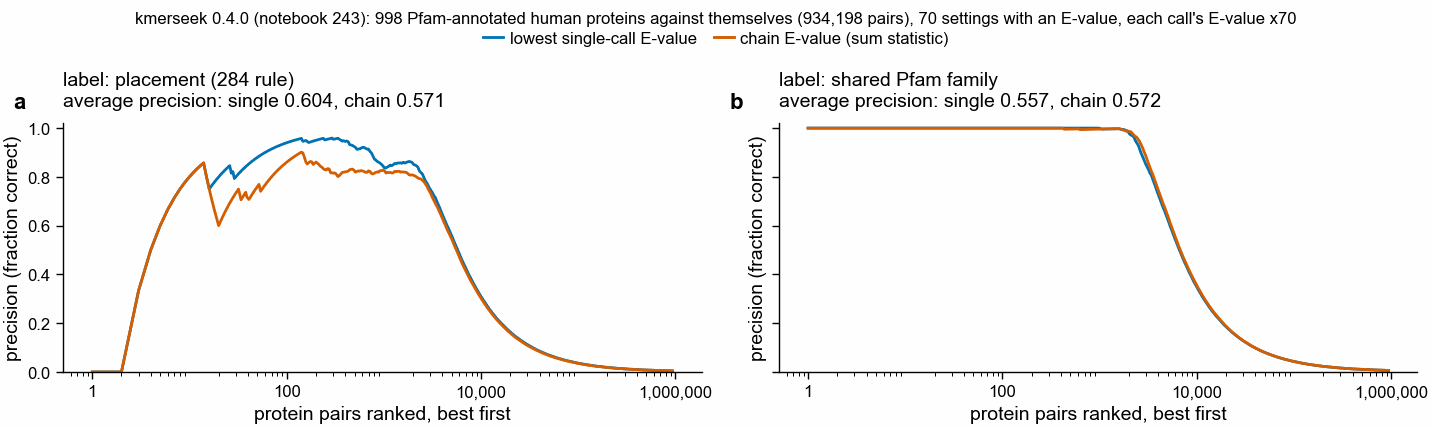

In [10]:
ap = pl.read_csv("287_pfam998_average_precision.csv")
print(ap)
curve = pl.read_csv("287_pfam998_precision_curve.csv")
fig, axs = pf.figure(pf.TWO_COLUMN_MM, 55, ncols=2, sharey=True)
for ax, lab, letter in zip(axs, ["placement (284 rule)", "shared Pfam family"], "ab"):
    a = ap.filter(pl.col("label") == lab).row(0, named=True)
    for score, sty, ap_val in (
        ("lowest single E-value", SINGLE, a["ap_single"]),
        ("chain E-value", CHAIN, a["ap_chain"]),
    ):
        c = curve.filter((pl.col("label") == lab) & (pl.col("score") == score))
        ax.plot(
            c["n_pairs"], c["precision"], color=sty["color"], lw=1, label=sty["label"]
        )
    ax.set_xscale("log")
    ax.set_xticks([1, 100, 10000, 1000000], ["1", "100", "10,000", "1,000,000"])
    ax.set_xlabel("protein pairs ranked, best first")
    ax.set_ylabel("precision (fraction correct)")
    ax.set_ylim(0, 1.02)
    ax.set_title(
        f"label: {lab}\naverage precision: single {a['ap_single']:.3f}, chain {a['ap_chain']:.3f}",
        loc="left",
    )
    pf.panel_label(ax, letter)
pf.shared_legend(
    fig,
    ncol=2,
    title="kmerseek 0.4.0 (notebook 243): 998 Pfam-annotated human proteins against themselves (934,198 pairs), 70 settings with an E-value, each call's E-value x70",
)
pf.save(fig, FIG / "287_pfam998_precision_by_rank_pfam998")

Why the two labels disagree: a chain reports one stretch, from its first call's start to
its last call's end, and that stretch is longer than any of its calls. Notebook 284's rule
needs one Pfam family to cover 20% of the reported stretch, which a long stretch across
several domains fails. The table splits the pairs by how many calls their best chain has,
with the median length of the chain's stretch and of the best single call's stretch, and the
fraction labelled correct each way. The two top-ranked pairs fail this way too: C4A and C4B
(P0C0L4, P0C0L5) match along all 1_744 residues and carry 11 Pfam domains, the longest 334
residues.

shape: (8, 7)
┌─────────┬─────────┬──────────────────────┬───────────────────────┬────────────────────┬─────────────────────┬────────────────────┐
│ chain_r ┆ n_pairs ┆ median_chain_stretch ┆ median_single_stretch ┆ frac_correct_chain ┆ frac_correct_single ┆ frac_shared_family │
│ ---     ┆ ---     ┆ ---                  ┆ ---                   ┆ ---                ┆ ---                 ┆ ---                │
│ i64     ┆ u32     ┆ f64                  ┆ f64                   ┆ f64                ┆ f64                 ┆ f64                │
╞═════════╪═════════╪══════════════════════╪═══════════════════════╪════════════════════╪═════════════════════╪════════════════════╡
│ 1       ┆ 926545  ┆ 27.000               ┆ 27.000                ┆ 0.002              ┆ 0.002               ┆ 0.004              │
│ 2       ┆ 6040    ┆ 143.000              ┆ 32.000                ┆ 0.128              ┆ 0.127               ┆ 0.152              │
│ 3       ┆ 842     ┆ 251.000              ┆ 59.000    

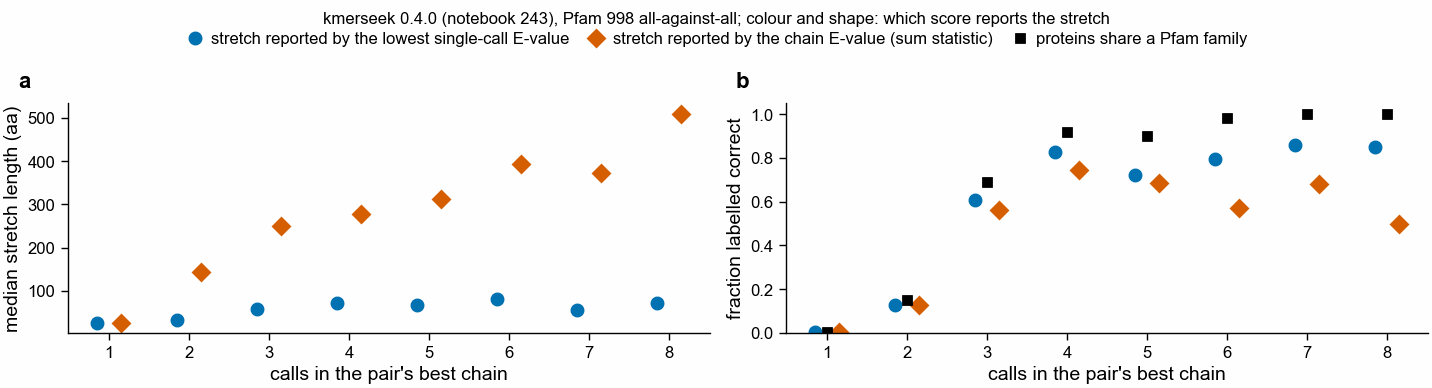

In [11]:
pairs = pl.read_parquet(
    "/Users/olga/data/alphabet-logreg-pfam998/287_pair_scores.parquet"
)
by_r = (
    pairs.with_columns(
        chain_len=pl.col("cqe") - pl.col("cqs"),
        single_len=pl.col("sqe") - pl.col("sqs"),
    )
    .group_by("chain_r")
    .agg(
        n_pairs=pl.len(),
        median_chain_stretch=pl.col("chain_len").median(),
        median_single_stretch=pl.col("single_len").median(),
        frac_correct_chain=pl.col("correct_c").mean(),
        frac_correct_single=pl.col("correct_s").mean(),
        frac_shared_family=pl.col("shared_family").mean(),
    )
    .sort("chain_r")
)
by_r.write_csv("287_pfam998_by_chain_length.csv")
print(by_r)
fig, axs = pf.figure(pf.TWO_COLUMN_MM, 50, ncols=2)
# side by side at each chain length (0.15 apart) so equal values do not hide each other
for sty, col, dx in ((SINGLE, "single", -0.15), (CHAIN, "chain", 0.15)):
    axs[0].plot(
        by_r["chain_r"] + dx,
        by_r[f"median_{col}_stretch"],
        marker=sty["marker"],
        color=sty["color"],
        ms=4,
        lw=0,
        label=f"stretch reported by the {sty['label']}",
    )
    axs[1].plot(
        by_r["chain_r"] + dx,
        by_r[f"frac_correct_{col}"],
        marker=sty["marker"],
        color=sty["color"],
        ms=4,
        lw=0,
    )
axs[1].plot(
    by_r["chain_r"],
    by_r["frac_shared_family"],
    marker="s",
    color="black",
    ms=3,
    lw=0,
    label="proteins share a Pfam family",
)
axs[0].set_ylabel("median stretch length (aa)")
axs[1].set_ylabel("fraction labelled correct")
axs[1].set_ylim(0, 1.05)
for ax, letter in zip(axs, "ab"):
    ax.set_xlabel("calls in the pair's best chain")
    ax.set_xticks(by_r["chain_r"].to_list())
    pf.panel_label(ax, letter)
pf.shared_legend(
    fig,
    ncol=3,
    title="kmerseek 0.4.0 (notebook 243), Pfam 998 all-against-all; colour and shape: which score reports the stretch",
)
pf.save(fig, FIG / "287_pfam998_stretch_by_chain_length_pfam998")

## 6. Shuffled copies of Ced9, P66 and BHF

The decision rule's parts (b) and (c) need the dipeptide-shuffled copies: 20 of each query
searched against the human proteome at all 152 settings with every region kept. That search
is notebook 284's (`notebooks/284_shuffle_agreement.sbatch`). It ran on 2026-10-20 (job
48677540) on notebook 283's rebuilt indexes, whose k-mer totals equal the N used here for
every setting. `scripts/287_shuffle_chains.sbatch` scores the copies with the same code as
the real queries (checked: on the real Ced9 and P66 calls it reproduces every number in
sections 2 and 3). Its first run (job 48677545) stopped at Ced9_shuf08, which has a call in
gbmr4 k21 or hp_lehninger_hpc3 k25, two fitted settings that no real query reached; it now
takes N for every fitted setting from the index logs. It writes `287_shuffle_chains.csv`,
which this cell reads.

284's run scores the real queries the same way 241's did: all 1_055_265 calls that have an
E-value in both runs have the same E-value, in every setting
(`287_check_284_matches_241.csv`, from `scripts/287_check_284_matches_241.py`). The one
difference: hp_lehninger_hpc3 k21 gave no call an E-value in 284's run (6 real-query calls
had one in 241's), so the shuffled copies are scored without that setting.

shape: (12, 11)
┌──────┬───────────────────────┬──────────┬───────────────────────┬───────────────────────┬───────────────────────┬───────────────────────┬───────────────────────┬───────────────────┬───────────────────────┬────────────┐
│ case ┆ variant               ┆ n_copies ┆ mean_proteins_chain_e ┆ max_proteins_chain_e_ ┆ frac_partner_chain_e_ ┆ n_copies_partner_with ┆ real_proteins_chain_e ┆ real_partner_rank ┆ copies_ranking_partne ┆ calibrated │
│ ---  ┆ ---                   ┆ ---      ┆ _below_1              ┆ below_1               ┆ below_1               ┆ out_call              ┆ _below_1              ┆ ---               ┆ r_at_least_as_high    ┆ ---        │
│ str  ┆ str                   ┆ u32      ┆ ---                   ┆ ---                   ┆ ---                   ┆ ---                   ┆ ---                   ┆ i64               ┆ ---                   ┆ bool       │
│      ┆                       ┆          ┆ f64                   ┆ i64                   ┆ f64     

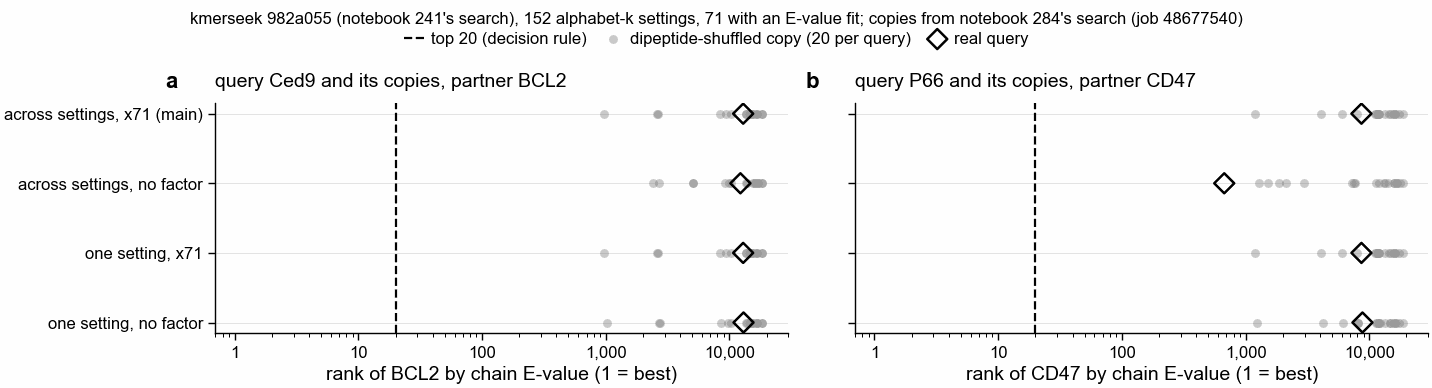

In [12]:
shuf = pl.read_csv("287_shuffle_chains.csv")
copies, real = shuf.filter(~pl.col("real")), shuf.filter(pl.col("real"))
# (b) and (c) of the decision rule, and where the real query sits among its copies
rule = (
    copies.group_by("case", "variant")
    .agg(
        n_copies=pl.len(),
        mean_proteins_chain_e_below_1=pl.col("n_chain_e_below_1").mean(),
        max_proteins_chain_e_below_1=pl.col("n_chain_e_below_1").max(),
        frac_partner_chain_e_below_1=(pl.col("partner_chain_e") < 1).mean(),
        n_copies_partner_without_call=pl.col("partner_chain_e").is_null().sum(),
        copy_partner_ranks=pl.col("partner_rank_chain").sort(),
    )
    .join(
        real.select(
            "case",
            "variant",
            real_proteins_chain_e_below_1="n_chain_e_below_1",
            real_partner_rank="partner_rank_chain",
        ),
        on=["case", "variant"],
    )
    .with_columns(
        # copies that rank the partner as high as the real query does, or higher
        copies_ranking_partner_at_least_as_high=pl.struct(
            "copy_partner_ranks", "real_partner_rank"
        ).map_elements(
            lambda s: sum(
                r is not None
                and s["real_partner_rank"] is not None
                and r <= s["real_partner_rank"]
                for r in s["copy_partner_ranks"]
            ),
            return_dtype=pl.Int64,
        ),
        calibrated=pl.col("mean_proteins_chain_e_below_1").is_between(0.3, 3),
    )
    .drop("copy_partner_ranks")
    .sort("case", "variant")
)
rule.write_csv("287_shuffle_decision_rule.csv")
print(rule)

fig, axs = pf.figure(pf.TWO_COLUMN_MM, 50, ncols=2, sharey=True)
COPY = dict(
    marker="o", color=pf.GREY, s=10, label="dipeptide-shuffled copy (20 per query)"
)
# hollow, so a copy with the same value stays visible underneath
REAL = dict(
    marker="D",
    facecolor="none",
    edgecolor="black",
    linewidths=0.9,
    s=26,
    label="real query",
)
yy = {v: i for i, v in enumerate(main4[::-1])}
for ax, (q, p), letter in zip(axs, [("Ced9", "BCL2"), ("P66", "CD47")], "ab"):
    for v in main4:
        ax.axhline(yy[v], color="#DDDDDD", lw=0.3, zorder=0)
    ax.axvline(20, color="black", ls="--", lw=0.8, label="top 20 (decision rule)")
    c = copies.filter(
        (pl.col("case") == q) & pl.col("variant").is_in(main4)
    ).drop_nulls("partner_rank_chain")
    ax.scatter(
        c["partner_rank_chain"],
        [yy[v] for v in c["variant"]],
        alpha=0.6,
        lw=0,
        zorder=2,
        **COPY,
    )
    r = real.filter((pl.col("case") == q) & pl.col("variant").is_in(main4))
    ax.scatter(r["partner_rank_chain"], [yy[v] for v in r["variant"]], zorder=3, **REAL)
    ax.set_xscale("log")
    ax.set_xlim(0.7, 30_000)
    ax.set_xticks([1, 10, 100, 1000, 10000], ["1", "10", "100", "1,000", "10,000"])
    ax.set_yticks(list(yy.values()), [label_of[v] for v in yy])
    ax.set_xlabel(f"rank of {p} by chain E-value (1 = best)")
    ax.set_title(f"query {q} and its copies, partner {p}", loc="left")
    pf.panel_label(ax, letter)
pf.shared_legend(
    fig, ncol=3, title=TOOLS + "; copies from notebook 284's search (job 48677540)"
)
pf.save(fig, FIG / "287_shuffled_copies_partner_rank_human_gencode")

Part (c), calibration: how many human proteins reach chain E-value below 1 in one search,
for each shuffled copy (no copy is related to any human protein, so every one of these is
by chance) and for the real query. The grey band is the decision rule's calibrated range,
0.3 to 3 per search.

shape: (12, 5)
┌──────┬────────────────────────────┬─────┬─────────┬─────┐
│ case ┆ variant                    ┆ min ┆ median  ┆ max │
│ ---  ┆ ---                        ┆ --- ┆ ---     ┆ --- │
│ str  ┆ str                        ┆ i64 ┆ f64     ┆ i64 │
╞══════╪════════════════════════════╪═════╪═════════╪═════╡
│ BHF  ┆ across settings, no factor ┆ 30  ┆ 48.500  ┆ 65  │
│ BHF  ┆ across settings, x71       ┆ 0   ┆ 0.000   ┆ 0   │
│ BHF  ┆ one setting, no factor     ┆ 2   ┆ 4.500   ┆ 10  │
│ BHF  ┆ one setting, x71           ┆ 0   ┆ 0.000   ┆ 0   │
│ Ced9 ┆ across settings, no factor ┆ 86  ┆ 108.500 ┆ 145 │
│ Ced9 ┆ across settings, x71       ┆ 0   ┆ 0.000   ┆ 0   │
│ Ced9 ┆ one setting, no factor     ┆ 2   ┆ 7.000   ┆ 21  │
│ Ced9 ┆ one setting, x71           ┆ 0   ┆ 0.000   ┆ 0   │
│ P66  ┆ across settings, no factor ┆ 170 ┆ 206.000 ┆ 258 │
│ P66  ┆ across settings, x71       ┆ 0   ┆ 0.000   ┆ 0   │
│ P66  ┆ one setting, no factor     ┆ 2   ┆ 5.000   ┆ 7   │
│ P66  ┆ one setting, x71

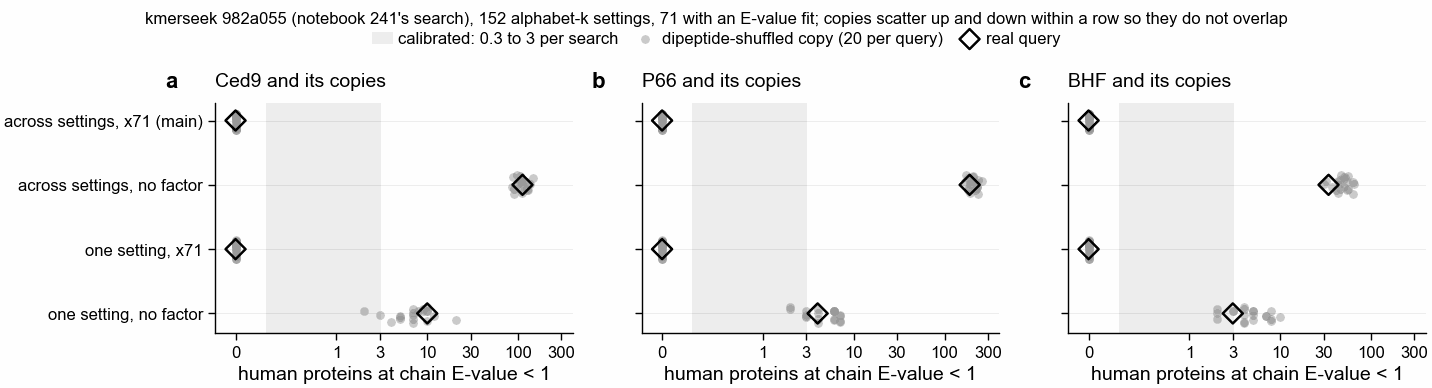

In [13]:
fig, axs = pf.figure(pf.TWO_COLUMN_MM, 50, ncols=3, sharey=True)
for ax, q, letter in zip(axs, ["Ced9", "P66", "BHF"], "abc"):
    ax.axvspan(
        0.3, 3, color="#EEEEEE", zorder=0, label="calibrated: 0.3 to 3 per search"
    )
    for v in main4:
        ax.axhline(yy[v], color="#DDDDDD", lw=0.3, zorder=0)
    c = copies.filter((pl.col("case") == q) & pl.col("variant").is_in(main4))
    jitter = np.random.default_rng(287).uniform(-0.15, 0.15, c.height)
    ax.scatter(
        c["n_chain_e_below_1"],
        [yy[v] + j for v, j in zip(c["variant"], jitter)],
        alpha=0.6,
        lw=0,
        zorder=2,
        **COPY,
    )
    r = real.filter((pl.col("case") == q) & pl.col("variant").is_in(main4))
    ax.scatter(r["n_chain_e_below_1"], [yy[v] for v in r["variant"]], zorder=3, **REAL)
    ax.set_xscale("symlog", linthresh=1)
    ax.set_xlim(-0.2, 400)
    ax.set_xticks(
        [0, 1, 3, 10, 30, 100, 300], ["0", "1", "3", "10", "30", "100", "300"]
    )
    ax.set_yticks(list(yy.values()), [label_of[v] for v in yy])
    ax.set_xlabel("human proteins at chain E-value < 1")
    ax.set_title(f"{q} and its copies", loc="left")
    pf.panel_label(ax, letter)
pf.shared_legend(
    fig,
    ncol=3,
    title=TOOLS + "; copies scatter up and down within a row so they do not overlap",
)
pf.save(fig, FIG / "287_shuffled_copies_chance_hits_human_gencode")
print(
    copies.filter(pl.col("variant").is_in(main4))
    .group_by("case", "variant")
    .agg(
        min=pl.col("n_chain_e_below_1").min(),
        median=pl.col("n_chain_e_below_1").median(),
        max=pl.col("n_chain_e_below_1").max(),
    )
    .sort("case", "variant")
)

## Summary and conclusions

**Verdict: no.** Combining Ced9's calls on BCL2 with BLAST's sum statistic does not rescue
the pair, under any way of counting the search tried here. Decision rule: (a) fails (BCL2
is rank 12_906, chain E-value 138_779); (b) holds (no shuffled copy gets BCL2 below
E-value 1); (c) fails in both directions (0 chance proteins per search with the factor of
71, 49 to 206 without it).

- With the main score (each call's E-value times 71, for the 71 settings that have an E-value fit),
  BCL2's best chain is the BH4 call alone, E-value 138_779, rank 12_906 of 19_732. Its
  BH4 + BH1 chain scores 422_827, worse than BH4 alone, because each call's E-value times 71
  is above the pair's chance level and adding it only adds to the count of chances taken.
  The 20th protein has E-value 93, so BCL2 is about 1_500 times short of the top 20.
- Without the factor of 71, BCL2's best chain is BH4 plus a hp_pbotc_1st_ed2 call off the
  BH motifs, E-value 1_204, rank 12_262. The BH4 + BH1 chain itself scores 1_280. Ced9 and
  BCL2 share two short, weak calls: a search of the proteome expects about 1_955 and
  11_173 calls that good by chance. Adding two weak scores gives a weak score.
- The family member chaining helps most is BAK1: three calls take it from rank 468 to 60
  (chain E-value 0.44), but only without the factor of 71, where 111 unrelated proteins
  also reach E-value below 1. MCL1, the family member with the best single call (E-value
  17, rank 321), gains nothing.
- P66 → CD47 behaves the same: rank 8_648 with the main score; rank 673 (E-value 5.4)
  without the factor, from a chain of four calls on four diagonals 165 residues apart, which
  is not one alignment.
- Chaining across settings without the factor of 71 is not calibrated: 111 proteins outside
  the BCL-2 family (Ced9), 190 (P66) and 34 (BHF) reach chain E-value below 1 in one search,
  against about 1 for a calibrated E-value. With the factor, none do (0 for all three
  queries), so the main score is conservative: the 71 settings are not independent, and it
  counts them as if they were.
- On the Pfam 998 all-against-all, the chain score is worse than the lowest single
  E-value by notebook 284's placement label (average precision 0.571 against 0.604), and
  slightly better if any shared Pfam family counts (0.572 against 0.557). The first-cell rule
  did not say which label; with the label the task specified (284's), chaining does not help.
  Only 7_653 of 934_198 protein pairs have a best chain of two or more calls. The
  placement loss comes from the stretch a chain reports, from its first call to its last,
  which is about 4 to 7 times longer than the best single call's and fails 284's 20% rule more
  often; the ranking itself is slightly better (the shared-family label).

**What this means for kmerseek.** Sum statistics are the right tool for joining several
weak ungapped calls, and kmerseek already has them inside one search (`--chain-max-gap`).
They cannot turn calls that are each 1_000 to 10_000 times above chance into a hit. Ced9 →
BCL2 needs longer or better calls, not a better way of adding the calls kmerseek already
makes. No kmerseek issue was filed: the rule for filing one ("if it works") was not met.

- **Shuffled copies** (20 dipeptide-shuffled copies of each query, section 6). Ced9 looks
  like its copies: 6 of 20 copies rank BCL2 as high as Ced9 does, or higher, with the main
  score. P66 without the factor ranks CD47 at 673, higher than all 20 of its copies, but
  that chain joins four calls on diagonals 165 residues apart, and P66's count of chance
  proteins at E-value below 1 (189) sits inside its copies' range (170 to 258).
- **Calibration.** With the factor of 71, no copy of any query reaches E-value below 1 for
  any human protein: the main score is too conservative. Without it, copies reach 30 to 258
  proteins per search. The best single call per protein, chosen across 71 settings with no
  factor, gives 0 to 20 (mean 5.2): kmerseek's own single-setting E-value is itself
  conservative, since picking the best of 71 settings would give about 71 if each setting
  were calibrated and independent.

**Not tested.** Chains with gaps inside a call (BLAST's gapped extension), and an
effective number of settings between 1 and 71, fitted on shuffled copies.